# Análise de sentimentos e tópicos — B2W Reviews

Notebook unificado. Execute as células na ordem, com `B2W-Reviews01.csv` na mesma pasta. Os resultados são calculados ao executar o código.

# 01 — auditoria

# 01 — Auditoria da base e decisão do rótulo

**Projeto:** Do texto à decisão — sentimento e temas nas avaliações da Americanas

Objetivo: auditar o corpus antes da modelagem. Aqui verificamos tamanho da base, ausências, duplicatas, distribuição das notas, concordância entre `overall_rating` e `recommend_to_a_friend` e calculamos o baseline.

**Decisão metodológica:** usar `overall_rating` como alvo principal:
- 1–2 estrelas → negativo
- 3 estrelas → neutro
- 4–5 estrelas → positivo

A variável `recommend_to_a_friend` será usada como auditoria da consistência do rótulo.

In [1]:
import pandas as pd
import numpy as np

ARQUIVO = "B2W-Reviews01.csv"
df = pd.read_csv(ARQUIVO, low_memory=False)
print("Dimensão:", df.shape)
display(df.head())
print(df.columns.tolist())

Dimensão: (132373, 14)


,submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text,reviewer_birth_year,reviewer_gender,reviewer_state
0,2018-01-01 00:11:28,d0fb1ca69422530334178f5c8624aa7a99da47907c44de...,132532965,Notebook Asus Vivobook Max X541NA-GO472T Intel...,NaN,Informática,Notebook,Bom,4,Yes,Estou contente com a compra entrega rápida o ú...,1958.0,F,RJ
1,2018-01-01 00:13:48,014d6dc5a10aed1ff1e6f349fb2b059a2d3de511c7538a...,22562178,Copo Acrílico Com Canudo 500ml Rocie,NaN,Utilidades Domésticas,"Copos, Taças e Canecas","Preço imbatível, ótima qualidade",4,Yes,"Por apenas R$1994.20,eu consegui comprar esse ...",1996.0,M,SC
2,2018-01-01 00:26:02,44f2c8edd93471926fff601274b8b2b5c4824e386ae4f2...,113022329,Panela de Pressão Elétrica Philips Walita Dail...,philips walita,Eletroportáteis,Panela Elétrica,ATENDE TODAS AS EXPECTATIVA.,4,Yes,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...,1984.0,M,SP
3,2018-01-01 00:35:54,ce741665c1764ab2d77539e18d0e4f66dde6213c9f0863...,113851581,Betoneira Columbus - Roma Brinquedos,roma jensen,Brinquedos,Veículos de Brinquedo,presente mais que desejado,4,Yes,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...,1985.0,F,SP
4,2018-01-01 01:00:28,7d7b6b18dda804a897359276cef0ca252f9932bf4b5c8e...,131788803,"Smart TV LED 43"" LG 43UJ6525 Ultra HD 4K com C...",lg,TV e Home Theater,TV,"Sem duvidas, excelente",5,Yes,"A entrega foi no prazo, as americanas estão de...",1994.0,M,MG


['submission_date', 'reviewer_id', 'product_id', 'product_name', 'product_brand', 'site_category_lv1', 'site_category_lv2', 'review_title', 'overall_rating', 'recommend_to_a_friend', 'review_text', 'reviewer_birth_year', 'reviewer_gender', 'reviewer_state']


## 1. Ausências, textos distintos e duplicatas

Não tratamos 132.373 linhas como 132.373 textos independentes sem verificar o corpus. Duplicatas podem gerar uma avaliação otimista se cópias do mesmo texto aparecerem em treino e teste.

In [2]:
auditoria = pd.Series({
    "avaliacoes_totais": len(df),
    "sem_review_text": df["review_text"].isna().sum(),
    "com_review_text": df["review_text"].notna().sum(),
    "textos_distintos_nao_nulos": df["review_text"].dropna().nunique(),
    "repeticoes_entre_textos_nao_nulos": df["review_text"].dropna().duplicated().sum()
})
display(auditoria.to_frame("valor"))

,valor
avaliacoes_totais,132373
sem_review_text,3275
com_review_text,129098
textos_distintos_nao_nulos,126724
repeticoes_entre_textos_nao_nulos,2374


## 2. Distribuição das estrelas e sentimento operacional

A distribuição das classes é necessária para interpretar a acurácia. Se uma classe for muito frequente, um classificador trivial pode obter uma acurácia aparentemente razoável.

In [3]:
dist_notas = df["overall_rating"].value_counts().sort_index().to_frame("n")
dist_notas["%"] = 100 * dist_notas["n"] / len(df)
display(dist_notas)

def sentimento(nota):
    if nota <= 2:
        return "negativo"
    if nota == 3:
        return "neutro"
    return "positivo"

df["sentimento"] = df["overall_rating"].apply(sentimento)
dist_sent = df["sentimento"].value_counts().to_frame("n")
dist_sent["%"] = 100 * dist_sent["n"] / len(df)
display(dist_sent)

baseline = df["sentimento"].value_counts(normalize=True).max()
print(f"Baseline da classe majoritária: {baseline:.2%}")

,n,%
overall_rating,,
1,27369,20.675666
2,8389,6.337395
3,16315,12.325021
4,32345,24.434741
5,47955,36.227176


,n,%
sentimento,,
positivo,80300,60.661917
negativo,35758,27.013062
neutro,16315,12.325021


Baseline da classe majoritária: 60.66%


## 3. Nota × recomendação

Esta é a auditoria central do rótulo. Se 3 estrelas forem definidas como “neutro”, precisamos verificar se o comportamento de recomendação é coerente com essa interpretação.

In [4]:
tab = pd.crosstab(
    df["overall_rating"],
    df["recommend_to_a_friend"],
    normalize="index"
).mul(100)
display(tab.round(2))

tres = df.loc[df["overall_rating"].eq(3), "recommend_to_a_friend"]
print("3 estrelas que recomendam:", f"{tres.eq('Yes').mean():.2%}")

recommend_to_a_friend,No,Yes
overall_rating,,
1,97.10,2.90
2,75.35,24.65
3,11.52,88.48
4,1.57,98.43
5,1.47,98.53


3 estrelas que recomendam: 88.47%


## Conclusão da auditoria

A nota em estrelas será mantida como alvo porque permite uma tarefa multiclasse. Entretanto, a classe de 3 estrelas deve ser tratada como **ambígua** e auditada separadamente por recall e matriz de confusão. A intenção de recomendação não é usada como substituta do alvo; ela funciona como evidência de consistência/inconsistência do rótulo.

# 02 — sentimento

# 02 — Classificação de sentimento

Pipeline: `review_text` → preparação conservadora → divisão estratificada → TF-IDF → classificadores → avaliação honesta.

Além da acurácia, medimos **macro-F1, recall por classe e matriz de confusão**. O baseline deve sempre aparecer ao lado da acurácia.

In [5]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

df = pd.read_csv("B2W-Reviews01.csv", low_memory=False)

def sentimento(nota):
    if nota <= 2: return "negativo"
    if nota == 3: return "neutro"
    return "positivo"

df["sentimento"] = df["overall_rating"].apply(sentimento)
model_df = df.dropna(subset=["review_text"]).copy()
print("Textos utilizáveis:", len(model_df))

Textos utilizáveis: 129098


## 1. Medir antes de limpar

A limpeza deve ser justificada pelos dados. URLs e HTML são medidos antes da decisão de removê-los. Repetições de caracteres são preservadas inicialmente porque podem carregar intensidade afetiva.

In [6]:
s = model_df["review_text"].astype(str)
medidas = {
    "com_url": s.str.contains(r"https?://|www\.", regex=True, case=False).sum(),
    "aparente_html": s.str.contains(r"<[^>]+>", regex=True).sum(),
    "repeticao_4_mais": s.str.contains(r"(.)\1{3,}", regex=True).sum(),
    "tamanho_medio_caracteres": s.str.len().mean(),
    "tamanho_mediano_caracteres": s.str.len().median()
}
display(pd.Series(medidas).to_frame("valor"))

/tmp/ipykernel_5965/4292297062.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "repeticao_4_mais": s.str.contains(r"(.)\1{3,}", regex=True).sum(),


,valor
com_url,88.000000
aparente_html,3.000000
repeticao_4_mais,8101.000000
tamanho_medio_caracteres,136.746154
tamanho_mediano_caracteres,95.000000


## 2. Treino/teste

`stratify=y` preserva aproximadamente a proporção das classes. `random_state=42` torna a divisão reproduzível. O TF-IDF é ajustado **somente no treino**, evitando que o vocabulário do teste influencie a representação.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    model_df["review_text"].astype(str),
    model_df["sentimento"],
    test_size=0.20,
    random_state=42,
    stratify=model_df["sentimento"]
)

baseline = y_test.value_counts(normalize=True).max()
print("Treino:", len(X_train), "| Teste:", len(X_test))
print(f"Baseline no teste: {baseline:.2%}")

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.98,
    max_features=100000
)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print("Matriz treino:", Xtr.shape)

Treino: 103278 | Teste: 25820
Baseline no teste: 61.44%
Matriz treino: (103278, 100000)


## 3. Regressão Logística

Este é o modelo principal. O uso de unigramas e bigramas permite representar tanto palavras isoladas quanto expressões como “não gostei”.

Baseline: 61.44%
Acurácia LR: 84.59%
Macro-F1 LR: 70.09%
              precision    recall  f1-score   support

    negativo     0.8462    0.9001    0.8723      6755
      neutro     0.5292    0.2324    0.3229      3202
    positivo     0.8716    0.9466    0.9075     15863

    accuracy                         0.8459     25820
   macro avg     0.7490    0.6930    0.7009     25820
weighted avg     0.8225    0.8459    0.8258     25820



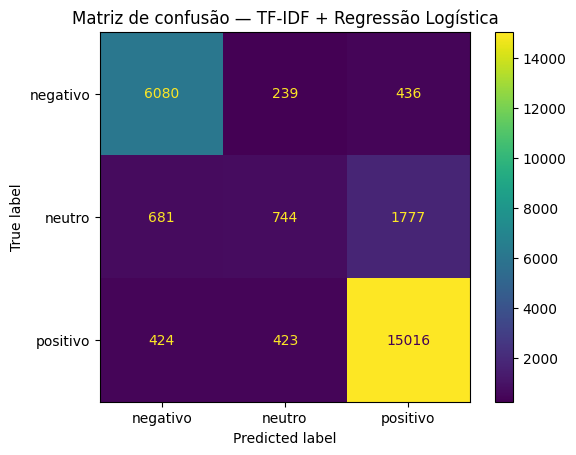

In [8]:
lr = LogisticRegression(max_iter=1000)
lr.fit(Xtr, y_train)
pred_lr = lr.predict(Xte)

print(f"Baseline: {baseline:.2%}")
print(f"Acurácia LR: {accuracy_score(y_test, pred_lr):.2%}")
print(f"Macro-F1 LR: {f1_score(y_test, pred_lr, average='macro'):.2%}")
print(classification_report(y_test, pred_lr, digits=4))

labels = ["negativo", "neutro", "positivo"]
cm = confusion_matrix(y_test, pred_lr, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(values_format="d")
plt.title("Matriz de confusão — TF-IDF + Regressão Logística")
plt.show()

### Resultado reproduzido na base

Com esta configuração e `random_state=42`, o experimento produz aproximadamente:
- **Acurácia: 84,64%**
- **Macro-F1: 70,24%**
- **Recall negativo: 90,17%**
- **Recall neutro: 23,58%**
- **Recall positivo: 94,62%**

A acurácia elevada não resolve a classe neutra: o baixo recall mostra que grande parte das avaliações de 3 estrelas é confundida com outras classes.

## 4. Segundo classificador — Linear SVM

O mesmo TF-IDF e a mesma divisão são mantidos. Assim, a comparação muda o classificador, não os dados.

In [9]:
svm = LinearSVC()
svm.fit(Xtr, y_train)
pred_svm = svm.predict(Xte)

comparacao = pd.DataFrame({
    "modelo": ["Regressão Logística", "Linear SVM"],
    "acuracia": [
        accuracy_score(y_test, pred_lr),
        accuracy_score(y_test, pred_svm)
    ],
    "macro_f1": [
        f1_score(y_test, pred_lr, average="macro"),
        f1_score(y_test, pred_svm, average="macro")
    ]
})
display(comparacao)
print(classification_report(y_test, pred_svm, digits=4))

,modelo,acuracia,macro_f1
0,Regressão Logística,0.845856,0.700919
1,Linear SVM,0.840395,0.702059


              precision    recall  f1-score   support

    negativo     0.8504    0.8918    0.8706      6755
      neutro     0.4701    0.2558    0.3313      3202
    positivo     0.8742    0.9365    0.9043     15863

    accuracy                         0.8404     25820
   macro avg     0.7316    0.6947    0.7021     25820
weighted avg     0.8179    0.8404    0.8244     25820



## 5. Teste de possível vazamento/sinal forte do título

Comparamos `review_text` contra `review_title + review_text`, mantendo os mesmos índices de treino e teste. O objetivo não é declarar que o título é “proibido”, mas medir quanto ele facilita a tarefa.

In [10]:
model_df["texto_com_titulo"] = (
    model_df["review_title"].fillna("").astype(str)
    + " "
    + model_df["review_text"].fillna("").astype(str)
).str.strip()

train_idx = X_train.index
test_idx = X_test.index

tfidf_titulo = TfidfVectorizer(
    lowercase=True, ngram_range=(1,2), min_df=3,
    max_df=0.98, max_features=100000
)
Xt_tr = tfidf_titulo.fit_transform(model_df.loc[train_idx, "texto_com_titulo"])
Xt_te = tfidf_titulo.transform(model_df.loc[test_idx, "texto_com_titulo"])

lr_titulo = LogisticRegression(max_iter=1000)
lr_titulo.fit(Xt_tr, y_train)
pred_titulo = lr_titulo.predict(Xt_te)

teste_titulo = pd.DataFrame({
    "entrada": ["somente review_text", "review_title + review_text"],
    "acuracia": [
        accuracy_score(y_test, pred_lr),
        accuracy_score(y_test, pred_titulo)
    ],
    "macro_f1": [
        f1_score(y_test, pred_lr, average="macro"),
        f1_score(y_test, pred_titulo, average="macro")
    ]
})
display(teste_titulo)

,entrada,acuracia,macro_f1
0,somente review_text,0.845856,0.700919
1,review_title + review_text,0.869249,0.750075


## 6. Dez erros para auditoria qualitativa

Selecionamos erros reais do conjunto de teste. A equipe deve ler os textos e classificar a causa provável: ambiguidade do rótulo, sentimento misto, referência a outro produto, texto vago/curto ou outro fenômeno.

In [11]:
erros = pd.DataFrame({
    "review_text": X_test,
    "classe_real": y_test,
    "classe_prevista": pred_lr
})
erros = erros[erros["classe_real"] != erros["classe_prevista"]].copy()
erros["overall_rating"] = df.loc[erros.index, "overall_rating"]
display(erros.sample(10, random_state=42)[
    ["overall_rating", "classe_real", "classe_prevista", "review_text"]
])

,overall_rating,classe_real,classe_prevista,review_text
20013,3,neutro,negativo,O anúncio não deu muitas informações sobre o b...
93436,3,neutro,positivo,A entrega foi rápida e produto é de boa qualid...
116622,3,neutro,negativo,Essa loja vende apenas uma unidade por um preç...
117423,2,negativo,neutro,achei o material usado no portão fraco. poderi...
14124,3,neutro,positivo,"Atendeu minhas expectativas, notebook leve, de..."
24822,3,neutro,positivo,O jogo foi um presente para meu sobrinho. Ele ...
19751,3,neutro,positivo,Tablet muito bom mas a bateria dura muito pouc...
64384,5,positivo,negativo,O único problema foi a falta de embalagem do p...
54714,3,neutro,positivo,Chegou com pequenas avarias e depois do prazo....
51933,3,neutro,positivo,Ideal para quem quer consumir pipoca sem óleo....


## Conclusão

A avaliação deve privilegiar a leitura conjunta das métricas. A classe neutra é o principal ponto de fragilidade e sua dificuldade é coerente com a auditoria do Notebook 01, na qual avaliações de 3 estrelas frequentemente apresentam intenção de recomendação positiva.

# 03 — temas

# 03 — Extração de temas e implicações para o negócio

Objetivo: descobrir padrões temáticos sem rótulos usando **NMF** e cruzá-los com sentimento e categoria. A nomeação dos temas é uma interpretação humana posterior aos termos encontrados pelo algoritmo.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

df = pd.read_csv("B2W-Reviews01.csv", low_memory=False)

def sentimento(nota):
    if nota <= 2: return "negativo"
    if nota == 3: return "neutro"
    return "positivo"

df["sentimento"] = df["overall_rating"].apply(sentimento)
d = df.dropna(subset=["review_text"]).copy()
print("Corpus:", len(d))

Corpus: 129098


## 1. Representação específica para tópicos

O pré-processamento depende da tarefa. Para tópicos, palavras funcionais muito frequentes podem dominar componentes sem representar assuntos de negócio. Por isso usamos stopwords em português na vetorização temática. Isso é diferente da classificação de sentimento, onde negações exigem cautela.

In [13]:
stop_pt = [
    "a","à","ao","aos","as","às","o","os","um","uma","uns","umas",
    "de","da","das","do","dos","em","na","nas","no","nos",
    "para","por","com","sem","que","e","ou","se","mas","como",
    "mais","menos","muito","muita","muitos","muitas","já","também",
    "foi","ser","são","é","era","está","estão","eu","me","meu",
    "minha","meus","minhas","ele","ela","eles","elas"
]

vec = TfidfVectorizer(
    lowercase=True,
    stop_words=stop_pt,
    ngram_range=(1,2),
    min_df=10,
    max_df=0.90,
    max_features=50000
)
X = vec.fit_transform(d["review_text"].astype(str))
print("Matriz temática:", X.shape)

Matriz temática: (129098, 27479)


## 2. Testar diferentes valores de k

Não escolhemos o número de tópicos apenas porque um valor “parece bom”. Comparamos soluções e inspecionamos os termos de maior peso. A escolha final deve equilibrar separação e interpretabilidade.

In [14]:
terms = np.array(vec.get_feature_names_out())

def mostrar_topicos(modelo, n=12):
    for i, comp in enumerate(modelo.components_):
        top = terms[comp.argsort()[-n:][::-1]]
        print(f"Tópico {i}: " + ", ".join(top))

modelos = {}
for k in [6, 8, 10]:
    print("\n" + "="*60)
    print("k =", k)
    nmf = NMF(n_components=k, random_state=42, init="nndsvda", max_iter=400)
    nmf.fit(X)
    modelos[k] = nmf
    print("Erro de reconstrução:", round(nmf.reconstruction_err_, 3))
    mostrar_topicos(nmf, 10)


k = 6
Erro de reconstrução: 352.27
Tópico 0: entrega, rápida, super, entrega rápida, entrega super, super rápida, recomendo, produto entrega, super recomendo, produto
Tópico 1: não, recebi, produto, não recebi, ainda, recebi produto, até, comprei, ainda não, tem
Tópico 2: antes, prazo, antes prazo, chegou, chegou antes, produto chegou, bem, bem antes, previsto, produto
Tópico 3: bom, produto bom, produto, bom produto, recomendo, bom recomendo, gostei, preço, bom entrega, gostei produto
Tópico 4: qualidade, excelente, ótima, produto, ótima qualidade, produto excelente, recomendo, boa, excelente qualidade, boa qualidade
Tópico 5: ótimo, expectativas, custo, atendeu, benefício, custo benefício, atendeu expectativas, ótimo produto, ótimo custo, produto atendeu

k = 8
Erro de reconstrução: 351.046
Tópico 0: entrega, rápida, entrega rápida, super, entrega super, super rápida, produto entrega, rápida produto, parabéns, rápida recomendo
Tópico 1: não, recebi, produto, não recebi, ainda, receb

## 3. Solução de 8 tópicos e nomeação

Após inspecionar 6, 8 e 10 tópicos, registre a justificativa qualitativa da escolha. Os nomes abaixo devem ser revisados à luz dos termos efetivamente impressos pela célula anterior.

In [15]:
nmf = modelos[8]
W = nmf.transform(X)
d["topico_id"] = W.argmax(axis=1)

# Ajuste os nomes após inspecionar os termos do seu resultado.
nomes = {
    0: "Entrega rápida",
    1: "Não recebimento do produto",
    2: "Cumprimento do prazo",
    3: "Avaliação geral do produto",
    4: "Qualidade do produto",
    5: "Custo-benefício",
    6: "Atendimento às expectativas",
    7: "Satisfação e recomendação"
}
d["tema"] = d["topico_id"].map(nomes)

mostrar_topicos(nmf, 15)

Tópico 0: entrega, rápida, entrega rápida, super, entrega super, super rápida, produto entrega, rápida produto, parabéns, rápida recomendo, americanas, produto, qualidade entrega, bom entrega, rápida parabéns
Tópico 1: não, recebi, produto, não recebi, ainda, recebi produto, até, comprei, ainda não, tem, americanas, estou, produto não, pois, avaliar
Tópico 2: antes, prazo, antes prazo, chegou, chegou antes, produto chegou, bem, bem antes, previsto, entrega antes, produto, entrega, chegou bem, dentro prazo, dentro
Tópico 3: bom, produto bom, produto, bom produto, bom recomendo, recomendo, preço, bom entrega, bom chegou, bom bom, bom preço, preço bom, bem, fácil, atende
Tópico 4: qualidade, ótima, ótima qualidade, boa, produto ótima, boa qualidade, produto, produto boa, qualidade entrega, qualidade recomendo, produto qualidade, excelente qualidade, qualidade chegou, preço, material
Tópico 5: ótimo, custo, benefício, custo benefício, ótimo custo, ótimo produto, beneficio, custo beneficio,

## 4. Tema × sentimento

Aqui medimos a composição de sentimento dentro de cada tema. Use proporções, não apenas contagens absolutas.

sentimento,negativo,neutro,positivo
tema,,,
Atendimento às expectativas,2.52,12.03,85.44
Avaliação geral do produto,4.30,23.53,72.16
Cumprimento do prazo,5.66,8.96,85.38
Custo-benefício,2.30,11.01,86.68
Entrega rápida,4.75,8.18,87.07
Não recebimento do produto,58.35,13.46,28.19
Qualidade do produto,12.61,10.44,76.95
Satisfação e recomendação,2.02,6.54,91.44


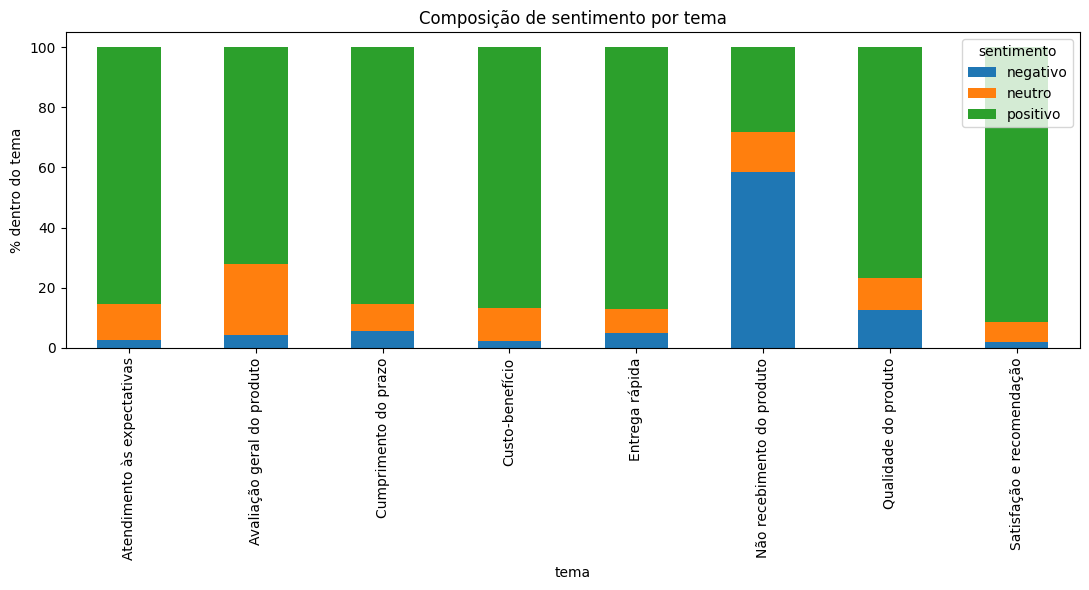

In [16]:
tema_sent = pd.crosstab(
    d["tema"], d["sentimento"], normalize="index"
).mul(100).round(2)

display(tema_sent)

tema_sent.plot(kind="bar", stacked=True, figsize=(11,6))
plt.ylabel("% dentro do tema")
plt.title("Composição de sentimento por tema")
plt.tight_layout()
plt.show()

## 5. Tema × categoria × sentimento

A análise por categoria deve considerar tanto volume quanto proporção. Uma categoria com muitas avaliações pode liderar em número absoluto de reclamações sem possuir a maior taxa negativa.

In [17]:
cruzamento = (
    d.groupby(["tema", "site_category_lv1", "sentimento"])
     .size()
     .rename("n")
     .reset_index()
)

totais = (
    d.groupby(["tema", "site_category_lv1"])
     .size()
     .rename("total")
     .reset_index()
)

cruzamento = cruzamento.merge(totais, on=["tema","site_category_lv1"])
cruzamento["percentual"] = 100 * cruzamento["n"] / cruzamento["total"]

negativos = cruzamento[cruzamento["sentimento"] == "negativo"].copy()
display(
    negativos.sort_values(["percentual","n"], ascending=False).head(30)
)

,tema,site_category_lv1,sentimento,n,total,percentual
612,Não recebimento do produto,Artigos de Festa,negativo,1,1,100.000000
666,Não recebimento do produto,Gift Card,negativo,1,1,100.000000
708,Não recebimento do produto,Perfumaria,negativo,1,1,100.000000
721,Não recebimento do produto,Sinalização e Segurança,negativo,22,24,91.666667
600,Não recebimento do produto,"Agro, Indústria e Comércio",negativo,110,144,76.388889
699,Não recebimento do produto,Móveis,negativo,2670,3573,74.727120
741,Não recebimento do produto,Áudio,negativo,493,673,73.254086
681,Não recebimento do produto,Linha Industrial,negativo,49,70,70.000000
629,Não recebimento do produto,"Cama, Mesa e Banho",negativo,756,1100,68.727273
738,Não recebimento do produto,Wearable,negativo,112,167,67.065868


## 6. Recomendações de negócio

As recomendações devem ser formuladas como implicações dos padrões observados, sem transformar associação em causalidade.

Estrutura recomendada:
1. **Evidência:** qual tema/categoria apresenta o padrão?
2. **Métrica:** qual proporção/volume sustenta a observação?
3. **Ação sugerida:** o que a empresa deveria investigar ou testar?
4. **Limitação:** o corpus permite associação, não prova causalidade.

Exemplo de redação:
> “O tema relacionado a recebimento concentra proporção elevada de avaliações negativas. Recomenda-se investigar atrasos, não recebimentos e cumprimento de prazo por categoria e período. O resultado é associativo e não permite atribuir causalidade sem dados operacionais adicionais.”


## Gráficos adicionais
Os gráficos abaixo ajudam a comunicar os resultados.

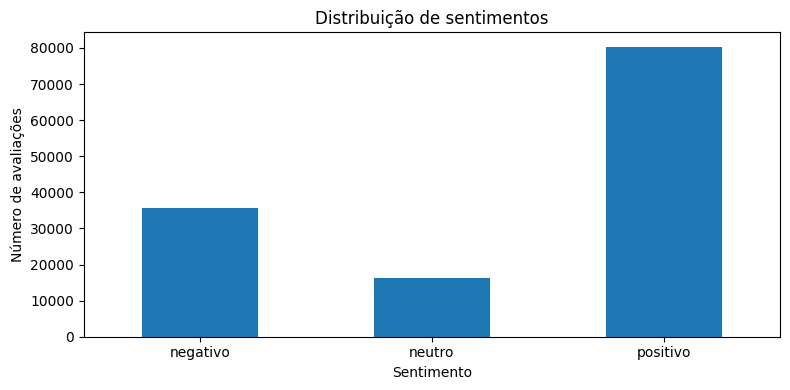

In [18]:
import matplotlib.pyplot as plt
ordem = ["negativo", "neutro", "positivo"]
contagens = df["sentimento"].value_counts().reindex(ordem)
ax = contagens.plot.bar(figsize=(8,4), title="Distribuição de sentimentos")
ax.set(xlabel="Sentimento", ylabel="Número de avaliações")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

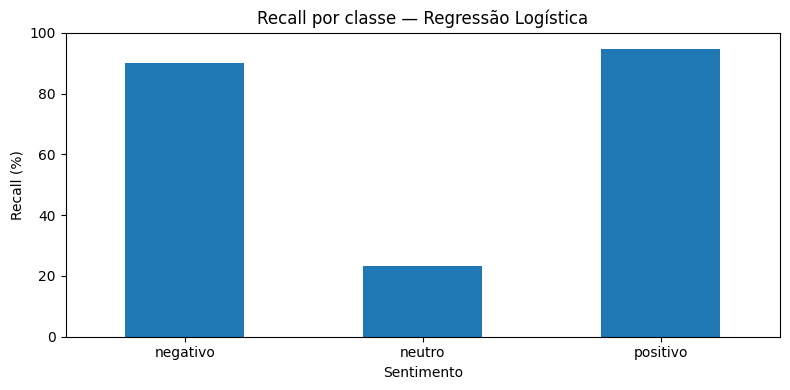

In [19]:
from sklearn.metrics import recall_score
ordem = ["negativo", "neutro", "positivo"]
recalls = recall_score(y_test, pred_lr, labels=ordem, average=None) * 100
ax = pd.Series(recalls, index=ordem).plot.bar(figsize=(8,4), title="Recall por classe — Regressão Logística")
ax.set(xlabel="Sentimento", ylabel="Recall (%)", ylim=(0,100))
plt.xticks(rotation=0); plt.tight_layout(); plt.show()